# Travelers' Inn — Exploratory Data Analysis

## AIAP Batch 25 Technical Assessment

This notebook explores booking records spanning 2023–2025 and post-stay guest reviews for Travelers' Inn's City Hotel and Airport Hotel.

The purpose of the EDA is to understand the quality and structure of the available data, identify booking patterns associated with reservation fall-through and determine which business problem is sufficiently supported by the data for an end-to-end machine learning solution, and determine which business problem is sufficiently supported by the data for an end-to-end machine learning solution.

## 1. Business Context and EDA Objectives

Travelers' Inn has identified several pressures on profitability, including:

- rooms becoming vacant due to cancellations and no-shows;
- difficulty anticipating which confirmed reservations may fall through;
- room rates being set largely through intuition;
- mixed customer perceptions of whether rooms are priced too cheaply or too expensively;
- no ability to increase room capacity or staffing.

The EDA therefore investigates the following questions:

1. What is the structure and quality of the available booking and review data?
2. How significant are cancellations and no-shows?
3. What booking characteristics appear associated with reservation fall-through?
4. How do room prices vary across hotels, time periods and booking characteristics?
5. What can guest reviews tell us about customer experience and perceived value?
6. Which business opportunity is best supported by the available data for machine learning?

In [1]:
from pathlib import Path
import sqlite3
import calendar

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DB_PATH = Path("data/hotel.db")

print("Database available:", DB_PATH.exists())

Database available: True


## 2. Data Loading and Dataset Overview

The assessment data is stored in a SQLite database. The database is queried directly rather than exporting the source tables into separate local files.

The first step is to identify the available tables, load them into pandas DataFrames, and establish the observation grain of each dataset.

In [2]:
with sqlite3.connect(DB_PATH) as conn:
    tables = pd.read_sql_query(
        """
        SELECT name
        FROM sqlite_master
        WHERE type = 'table'
        ORDER BY name
        """,
        conn,
    )

tables

,name
0,bookings
1,reviews


In [3]:
with sqlite3.connect(DB_PATH) as conn:
    bookings = pd.read_sql_query("SELECT * FROM bookings", conn)
    reviews = pd.read_sql_query("SELECT * FROM reviews", conn)

print(f"Bookings shape: {bookings.shape}")
print(f"Reviews shape:  {reviews.shape}")

Bookings shape: (118549, 36)
Reviews shape:  (17583, 3)


In [4]:
dataset_overview = pd.DataFrame({
    "Dataset": ["bookings", "reviews"],
    "Rows": [len(bookings), len(reviews)],
    "Columns": [bookings.shape[1], reviews.shape[1]]
})

dataset_overview

,Dataset,Rows,Columns
0,bookings,118549,36
1,reviews,17583,3


### Initial observations

The database contains two datasets at different grains:

- `bookings` contains 118,549 reservation records and 36 attributes.
- `reviews` contains 17,583 post-stay guest reviews and 3 attributes.

The considerably smaller review dataset indicates that review information is available only for a subset of customers/bookings. The relationship between the two datasets therefore needs to be examined before any direct join is performed.

In [5]:
print("Booking columns:")
display(pd.DataFrame({
    "Column": bookings.columns,
    "Pandas dtype": bookings.dtypes.astype(str).values
}))

print("\nReview columns:")
display(pd.DataFrame({
    "Column": reviews.columns,
    "Pandas dtype": reviews.dtypes.astype(str).values
}))

Booking columns:


,Column,Pandas dtype
0,Unnamed: 0,str
1,booking_id,str
2,client_email,str
3,hotel,str
4,is_canceled,str
5,lead_time,str
6,arrival_date_year,str
7,arrival_date_month,str
8,arrival_date_week_number,str
9,arrival_date_day_of_month,str



Review columns:


,Column,Pandas dtype
0,client_email,str
1,rating,str
2,comments,str


In [6]:
print("Bookings sample:")
display(
    bookings
    .drop(columns=["client_email"])
    .head()
)

print("\nReviews sample:")
display(
    reviews
    .drop(columns=["client_email"])
    .head()
)

Bookings sample:


,Unnamed: 0,booking_id,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,promo_code
0,112427,SG134998,Airport Hotel,0,94,2025,May,20,16,0,3,2,0,0,BB,OTH,Online TA,TA/TO,0,0,0,D,D,2,No Deposit,240.0,,0,Transient,230,0,1,Check-Out,2025-05-19 00:00:00,EARLYBIRD
1,95089,SG109835,Airport Hotel,1,103,2025,March,13,27,1,1,2,0,0,BB,SGP,Groups,Corporate,0,0,0,E,E,0,Non Refund,495.0,Kallang Industries,0,Transient,167.9,0,0,Canceled,2024-12-23 00:00:00,
2,78527,SG207272,City Hotel,0,83,2025,Apr,17,23,2,3,2,0,0,BB,JPN,Online TA,TA/TO,0,0,0,A,A,1,No Deposit,9.0,,0,Transient,27.6,0,2,Check-Out,2025-04-28 00:00:00,STAY3PAY2
3,76840,SG115106,Airport Hotel,0,48,2023,August,35,27,1,3,2,0,0,BB,CHN,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,196.0,,0,Transient,246.1,1,0,Check-Out,2023-08-31 00:00:00,FLASH
4,1167,SG182301,City Hotel,0,1,2024,March,11,9,0,1,1,0,0,BB,HKG,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,,0,Transient-Party,218.5,0,0,Check-Out,2024-03-10 00:00:00,



Reviews sample:


,rating,comments
0,4,"A hassle-free stay. The room was bright, nothi..."
1,5,A world-class stay — the staff went above and ...
2,5,Couldn't have asked for more — the team could ...
3,4,"A fuss-free stay. Check-in was smooth, a relia..."
4,5,An unforgettable stay. The team could not do e...


## 3. Data Quality Assessment

Before analysing business patterns, the datasets are assessed for:

- unexpected columns;
- duplicate records and identifier uniqueness;
- missing or blank values;
- incorrect data types;
- inconsistent categorical encodings;
- implausible numerical values;
- consistency between related fields;
- potential issues when joining bookings and reviews.

These checks are important because incorrect types, inconsistent labels or duplicated joins can materially distort both exploratory findings and downstream machine learning.

### 3.1 Structural checks and identifier uniqueness

The first checks assess whether the datasets contain unexpected columns and whether the stated identifiers behave as expected.

For the bookings data, `booking_id` is expected to uniquely identify each reservation. The `Unnamed: 0` field is also investigated because it is not part of the provided data dictionary and may represent an exported row index rather than a meaningful business attribute.

In [7]:
# Investigate duplicated booking identifiers

duplicate_booking_rows = bookings.loc[
    bookings["booking_id"].duplicated(keep=False)
].sort_values("booking_id")

print(
    "Rows belonging to duplicated booking_id groups:",
    len(duplicate_booking_rows)
)

print(
    "Number of duplicated booking_id groups:",
    duplicate_booking_rows["booking_id"].nunique()
)

print(
    "Exact full-row duplicates:",
    bookings.duplicated().sum()
)

columns_without_export_index = [
    col for col in bookings.columns
    if col != "Unnamed: 0"
]

print(
    "Duplicate rows excluding Unnamed: 0:",
    bookings.duplicated(
        subset=columns_without_export_index
    ).sum()
)

Rows belonging to duplicated booking_id groups: 706
Number of duplicated booking_id groups: 353
Exact full-row duplicates: 353
Duplicate rows excluding Unnamed: 0: 353


In [8]:
duplicate_booking_rows[
    [
        "Unnamed: 0",
        "booking_id",
        "client_email",
        "hotel",
        "is_canceled",
        "arrival_date_year",
        "arrival_date_month",
        "arrival_date_day_of_month",
        "reservation_status",
    ]
].head(20)

,Unnamed: 0,booking_id,client_email,hotel,is_canceled,arrival_date_year,arrival_date_month,arrival_date_day_of_month,reservation_status
5558,18013,SG100003,david.lim1660@gmail.com,Airport Hotel,1,2023,August,1,Canceled
61271,18013,SG100003,david.lim1660@gmail.com,Airport Hotel,1,2023,August,1,Canceled
88601,25992,SG100873,yuki.ng2446@outlook.com,Airport Hotel,0,2023,September,10,Check-Out
3978,25992,SG100873,yuki.ng2446@outlook.com,Airport Hotel,0,2023,September,10,Check-Out
91472,93931,SG101268,kai.sim2115@hotmail.com,Airport Hotel,0,2023,October,1,Check-Out
38151,93931,SG101268,kai.sim2115@hotmail.com,Airport Hotel,0,2023,October,1,Check-Out
31093,115868,SG101750,aisha.low5194@outlook.com,Airport Hotel,0,2023,October,23,Check-Out
18242,115868,SG101750,aisha.low5194@outlook.com,Airport Hotel,0,2023,October,23,Check-Out
85584,117308,SG102049,chloe.see2068@outlook.com,Airport Hotel,0,2023,November,5,Check-Out
51290,117308,SG102049,chloe.see2068@outlook.com,Airport Hotel,0,2023,November,5,Check-Out


In [9]:
print(
    "Exact duplicate review rows:",
    reviews.duplicated().sum()
)

duplicate_review_emails = reviews.loc[
    reviews["client_email"].duplicated(keep=False)
].sort_values("client_email")

print(
    "Rows belonging to repeated review emails:",
    len(duplicate_review_emails)
)

print(
    "Repeated customer email groups:",
    duplicate_review_emails["client_email"].nunique()
)

Exact duplicate review rows: 51
Rows belonging to repeated review emails: 102
Repeated customer email groups: 51


In [10]:
duplicate_review_emails[
    ["rating", "comments"]
].head(20)

,rating,comments
609,4,"A pleasant stay. The front desk was helpful, w..."
11762,4,"A pleasant stay. The front desk was helpful, w..."
11936,4,"A satisfying stay; the facilities were good, a..."
17004,4,"A satisfying stay; the facilities were good, a..."
8399,5,The staff went above and beyond; an outstandin...
16343,5,The staff went above and beyond; an outstandin...
406,5,"Fantastic stay; the room was spotless, a stand..."
1797,5,"Fantastic stay; the room was spotless, a stand..."
7513,3,"It was fine. The place was clean enough, just ..."
5481,3,"It was fine. The place was clean enough, just ..."


In [11]:
print("Bookings rows:", len(bookings))
print("Unique booking_id:", bookings["booking_id"].nunique())
print("Duplicate booking_id rows:", bookings["booking_id"].duplicated().sum())

print("\nUnnamed: 0")
print("Unique values:", bookings["Unnamed: 0"].nunique())
print("Duplicate values:", bookings["Unnamed: 0"].duplicated().sum())
print("First 10 values:")
display(bookings["Unnamed: 0"].head(10))

Bookings rows: 118549
Unique booking_id: 118196
Duplicate booking_id rows: 353

Unnamed: 0
Unique values: 118196
Duplicate values: 353
First 10 values:


0    112427
1     95089
2     78527
3     76840
4      1167
5     52781
6    119241
7     50455
8     95463
9      2916
Name: Unnamed: 0, dtype: str

### 3.2 Customer identifier and dataset grain

`client_email` links the bookings and reviews datasets. However, a customer may have more than one booking or review. Its uniqueness is therefore checked before joining the two datasets, as a many-to-many relationship could unintentionally duplicate observations.

In [12]:
email_grain = pd.DataFrame({
    "Dataset": ["bookings", "reviews"],
    "Rows": [len(bookings), len(reviews)],
    "Unique client_email": [
        bookings["client_email"].nunique(),
        reviews["client_email"].nunique()
    ],
    "Duplicated client_email rows": [
        bookings["client_email"].duplicated().sum(),
        reviews["client_email"].duplicated().sum()
    ]
})

email_grain

,Dataset,Rows,Unique client_email,Duplicated client_email rows
0,bookings,118549,118196,353
1,reviews,17583,17532,51


### 3.3 Booking-review relationship

Before combining the two datasets, the relationship between bookings and reviews is assessed using `client_email`.

A direct join is not assumed to be one-to-one. This prevents duplicated bookings or reviews from unintentionally altering counts and rates in later analysis.

In [13]:
booking_emails = set(bookings["client_email"].dropna())
review_emails = set(reviews["client_email"].dropna())

join_summary = pd.DataFrame({
    "Metric": [
        "Booking rows with a matching review email",
        "Unique booking customers with a review",
        "Review rows with a matching booking email"
    ],
    "Count": [
        bookings["client_email"].isin(review_emails).sum(),
        bookings.loc[
            bookings["client_email"].isin(review_emails),
            "client_email"
        ].nunique(),
        reviews["client_email"].isin(booking_emails).sum()
    ]
})

join_summary

,Metric,Count
0,Booking rows with a matching review email,17581
1,Unique booking customers with a review,17532
2,Review rows with a matching booking email,17583


In [14]:
raw_review_join = bookings[["booking_id", "client_email"]].merge(
    reviews[["client_email"]],
    on="client_email",
    how="inner"
)

print("Rows after raw inner join:", len(raw_review_join))

Rows after raw inner join: 17632


### 3.4 Missing and blank values

Because the SQLite tables store fields as text, missing information may appear either as true null values or as empty strings. Both forms are assessed to avoid understating missingness.

In [15]:
def missing_summary(df):
    true_nulls = df.isna().sum()

    blank_strings = (
        df.astype("string")
          .apply(lambda col: col.str.strip().eq("").sum())
    )

    summary = pd.DataFrame({
        "Null Count": true_nulls,
        "Blank String Count": blank_strings
    })

    summary["Total Missing/Blank"] = (
        summary["Null Count"] + summary["Blank String Count"]
    )

    summary["Percent Missing/Blank"] = (
        summary["Total Missing/Blank"] / len(df) * 100
    ).round(2)

    return summary.sort_values(
        "Percent Missing/Blank",
        ascending=False
    )

booking_missing = missing_summary(bookings)
review_missing = missing_summary(reviews)

display(booking_missing)
display(review_missing)

,Null Count,Blank String Count,Total Missing/Blank,Percent Missing/Blank
company,0,83513,83513,70.45
promo_code,0,48491,48491,40.90
agent,0,16281,16281,13.73
country,0,824,824,0.70
customer_type,0,383,383,0.32
arrival_date_week_number,0,362,362,0.31
meal,0,362,362,0.31
distribution_channel,0,344,344,0.29
market_segment,0,325,325,0.27
arrival_date_month,0,0,0,0.00


,Null Count,Blank String Count,Total Missing/Blank,Percent Missing/Blank
comments,0,332,332,1.89
client_email,0,0,0,0.00
rating,0,0,0,0.00


### 3.5 Data type validation

The SQLite schema stores all attributes as text, including variables that conceptually represent integers, continuous numerical values, binary indicators and dates.

These fields must therefore be validated and converted to suitable analytical types before descriptive statistics or machine learning are performed.

In [16]:
numeric_columns = [
    "is_canceled",
    "lead_time",
    "arrival_date_year",
    "arrival_date_week_number",
    "arrival_date_day_of_month",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "days_in_waiting_list",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

In [17]:
conversion_check = []

for col in [c for c in numeric_columns if c != "is_canceled"]:
    converted = pd.to_numeric(bookings[col], errors="coerce")

    original_nonblank = (
        bookings[col]
        .astype("string")
        .str.strip()
        .ne("")
        .fillna(False)
    )

    failed = original_nonblank & converted.isna()

    conversion_check.append({
        "Column": col,
        "Non-blank values": int(original_nonblank.sum()),
        "Failed numeric conversions": int(failed.sum())
    })

conversion_check = pd.DataFrame(conversion_check)

conversion_check

,Column,Non-blank values,Failed numeric conversions
0,lead_time,118549,50
1,arrival_date_year,118549,0
2,arrival_date_week_number,118187,128
3,arrival_date_day_of_month,118549,0
4,stays_in_weekend_nights,118549,0
5,stays_in_week_nights,118549,0
6,adults,118549,0
7,children,118549,0
8,babies,118549,0
9,is_repeated_guest,118549,0


In [18]:
def inspect_failed_numeric_values(df, column):
    numeric_version = pd.to_numeric(
        df[column],
        errors="coerce"
    )

    raw = (
        df[column]
        .astype("string")
        .str.strip()
    )

    invalid_mask = (
        raw.ne("")
        & numeric_version.isna()
    )

    return (
        raw[invalid_mask]
        .value_counts(dropna=False)
        .rename_axis("Raw Value")
        .reset_index(name="Count")
    )


for col in [
    "lead_time",
    "arrival_date_week_number",
    "adr"
]:
    print(f"\nInvalid values in {col}:")
    display(
        inspect_failed_numeric_values(
            bookings,
            col
        )
    )


Invalid values in lead_time:


,Raw Value,Count
0,1 days,4
1,14 days,3
2,99 days,2
3,24 days,2
4,2 days,2
5,6 days,2
6,0 days,2
7,83 days,2
8,17 days,2
9,192 days,1



Invalid values in arrival_date_week_number:


,Raw Value,Count
0,unknown,66
1,-,62



Invalid values in adr:


,Raw Value,Count
0,"0,00",6
1,"276,00",5
2,"149,50",5
3,"172,50",4
4,SGD 172.50,4
...,...,...
243,"170,77",1
244,"215,62",1
245,"658,38",1
246,SGD 204.93,1


### 3.6 Cancellation target consistency

The `is_canceled` field is intended to represent a binary reservation outcome. Its raw values are examined before numerical conversion because inconsistent categorical representations can produce incorrect cancellation rates.

In [19]:
# Use one row per reservation for target validation so known exact
# duplicate source records do not distort the outcome distribution.

target_eda = (
    bookings
    .drop_duplicates()
    [["is_canceled", "reservation_status"]]
    .copy()
)

cancel_mapping = {
    "0": 0,
    "no": 0,
    "false": 0,
    "1": 1,
    "yes": 1,
    "true": 1
}

target_eda["fall_through_flag"] = (
    target_eda["is_canceled"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(cancel_mapping)
)

print(
    "Unmapped target values:",
    target_eda["fall_through_flag"].isna().sum()
)

display(
    pd.crosstab(
        target_eda["fall_through_flag"],
        target_eda["reservation_status"],
        margins=True
    )
)

reservation_outcomes = (
    target_eda["reservation_status"]
    .value_counts()
    .rename_axis("Reservation Status")
    .reset_index(name="Bookings")
)

reservation_outcomes["Percent"] = (
    reservation_outcomes["Bookings"]
    / len(target_eda)
    * 100
).round(2)

reservation_outcomes

Unmapped target values: 0


reservation_status,Canceled,Check-Out,No-Show,All
fall_through_flag,,,,
0,0,75168,0,75168
1,41849,0,1179,43028
All,41849,75168,1179,118196


,Reservation Status,Bookings,Percent
0,Check-Out,75168,63.60
1,Canceled,41849,35.41
2,No-Show,1179,1.00


In [20]:
bookings["is_canceled"].value_counts(dropna=False)

is_canceled
0        73910
1        42312
false      776
No         712
Yes        427
true       412
Name: count, dtype: int64

In [21]:
pd.crosstab(
    bookings["is_canceled"],
    bookings["reservation_status"],
    margins=True
)

reservation_status,Canceled,Check-Out,No-Show,All
is_canceled,,,,
0,0,73910,0,73910
1,41153,0,1159,42312
No,0,712,0,712
Yes,415,0,12,427
false,0,776,0,776
true,401,0,11,412
All,41969,75398,1182,118549


### Target consistency finding

The raw `is_canceled` field uses three different representations of the same binary outcome (`0/1`, `No/Yes`, and `false/true`). Despite the inconsistent encoding, these representations are fully consistent with `reservation_status`.

After excluding known exact duplicate source records for this analysis, 43,028 of 118,196 reservations (36.40%) represent bookings that ultimately fell through. This comprises 41,849 cancellations (35.41%) and 1,179 no-shows (1.00%).

This confirms that reservation fall-through is a material business issue in the available data and provides a viable candidate target for predictive modelling. However, cancellation prediction is not selected as the final ML problem at this stage; subsequent EDA will assess its business relevance, actionability and available predictive signal.

**Modelling implication:** `reservation_status` and `reservation_status_date` describe the final outcome of a booking and are therefore not suitable predictors for a model intended to estimate cancellation/no-show risk before arrival. Including them would introduce target leakage.

They remain useful during EDA for validating the target definition, but they will be excluded from predictive features.

### 3.7 Data quality findings and pipeline implications

The initial data-quality assessment identified several issues that must be addressed before modelling:

- The bookings and reviews tables contain exact duplicate source records.
- `Unnamed: 0` appears to be a non-business export/index field.
- Missing information is predominantly represented by blank strings rather than database nulls, and some fields such as `agent`, `company`, and `promo_code` may represent meaningful absence.
- Several numeric fields contain inconsistent textual formatting. Examples include values such as `"14 days"` in `lead_time` and currency/decimal formatting variants in `adr`.
- The raw `is_canceled` target uses inconsistent binary representations, although these are consistent with the final reservation outcome.
- Outcome-related fields such as `reservation_status` and `reservation_status_date` would introduce leakage if used as predictors for a pre-outcome model.

These findings will inform preprocessing in the end-to-end ML pipeline, which will ingest the raw SQLite data directly. For EDA calculations, known source issues are handled temporarily in memory where necessary so that descriptive results are not distorted. No separate cleaned dataset is produced from the notebook.

## 4. Reservation Outcomes and Timing

The stakeholder reported that confirmed bookings are frequently lost at the last minute through cancellations and no-shows.

This section investigates whether the historical data supports that concern by first validating the reservation dates and then measuring how far in advance cancellations are recorded.

`reservation_status_date` is used only for retrospective EDA. Because it records outcome-time information, it would not be available as a predictor for a model intended to estimate fall-through risk before the outcome occurs.

In [22]:
# Temporary in-memory frame for accurate EDA statistics.
# Nothing is exported or written as a cleaned dataset.

bookings_eda = bookings.drop_duplicates().copy()

print(f"Raw booking rows: {len(bookings):,}")
print(f"Rows used for EDA: {len(bookings_eda):,}")
print(
    f"Exact duplicate rows excluded: "
    f"{len(bookings) - len(bookings_eda):,}"
)

Raw booking rows: 118,549
Rows used for EDA: 118,196
Exact duplicate rows excluded: 353


### 4.1 Arrival-date validation

Before analysing cancellation timing, the separate arrival year, month and day fields are combined into a calendar date. The raw month representations are inspected first because the data-quality assessment indicated inconsistent text formatting in several source fields.

In [23]:
month_value_counts = (
    bookings_eda["arrival_date_month"]
    .astype("string")
    .str.strip()
    .value_counts(dropna=False)
    .rename_axis("Raw Month Value")
    .reset_index(name="Bookings")
)

month_value_counts

,Raw Month Value,Bookings
0,August,13161
1,May,11780
2,March,11070
3,October,10600
4,April,10553
5,June,10372
6,September,9967
7,July,9389
8,February,7621
9,November,6416


In [24]:
month_lookup = {}

for month_num in range(1, 13):
    month_lookup[
        calendar.month_name[month_num].lower()
    ] = month_num

    month_lookup[
        calendar.month_abbr[month_num].lower()
    ] = month_num

month_text = (
    bookings_eda["arrival_date_month"]
    .astype("string")
    .str.strip()
    .str.lower()
)

bookings_eda["arrival_month_num"] = (
    month_text.map(month_lookup)
)

unrecognised_months = (
    bookings_eda.loc[
        bookings_eda["arrival_month_num"].isna(),
        "arrival_date_month"
    ]
    .value_counts(dropna=False)
)

print(
    "Rows with unrecognised month values:",
    bookings_eda["arrival_month_num"].isna().sum()
)

if len(unrecognised_months) > 0:
    display(unrecognised_months)

Rows with unrecognised month values: 0


In [25]:
arrival_year = pd.to_numeric(
    bookings_eda["arrival_date_year"],
    errors="coerce"
)

arrival_day = pd.to_numeric(
    bookings_eda["arrival_date_day_of_month"],
    errors="coerce"
)

bookings_eda["arrival_date"] = pd.to_datetime(
    pd.DataFrame({
        "year": arrival_year,
        "month": bookings_eda["arrival_month_num"],
        "day": arrival_day
    }),
    errors="coerce"
)

arrival_date_summary = pd.DataFrame({
    "Metric": [
        "Rows analysed",
        "Invalid arrival dates",
        "Earliest arrival date",
        "Latest arrival date"
    ],
    "Value": [
        len(bookings_eda),
        bookings_eda["arrival_date"].isna().sum(),
        bookings_eda["arrival_date"].min(),
        bookings_eda["arrival_date"].max()
    ]
})

arrival_date_summary

,Metric,Value
0,Rows analysed,118196
1,Invalid arrival dates,0
2,Earliest arrival date,2023-08-01 00:00:00
3,Latest arrival date,2025-08-31 00:00:00


In [26]:
status_text = (
    bookings_eda["reservation_status_date"]
    .astype("string")
    .str.strip()
)

status_date = pd.Series(
    pd.NaT,
    index=bookings_eda.index,
    dtype="datetime64[ns]"
)

# Standard YYYY-MM-DD timestamps
mask_iso = status_text.str.match(
    r"^\d{4}-\d{2}-\d{2}(?: \d{2}:\d{2}:\d{2})?$",
    na=False
)

status_date.loc[mask_iso] = pd.to_datetime(
    status_text.loc[mask_iso],
    format="mixed",
    errors="coerce"
)

# DD/MM/YYYY
mask_slash = status_text.str.match(
    r"^\d{1,2}/\d{1,2}/\d{4}$",
    na=False
)

status_date.loc[mask_slash] = pd.to_datetime(
    status_text.loc[mask_slash],
    format="%d/%m/%Y",
    errors="coerce"
)

# MM-DD-YY
mask_dash = status_text.str.match(
    r"^\d{1,2}-\d{1,2}-\d{2}$",
    na=False
)

status_date.loc[mask_dash] = pd.to_datetime(
    status_text.loc[mask_dash],
    format="%m-%d-%y",
    errors="coerce"
)

# DD Mon YYYY / DD Month YYYY
mask_text = status_text.str.match(
    r"^\d{1,2}\s+[A-Za-z]+\s+\d{4}$",
    na=False
)

status_date.loc[mask_text] = pd.to_datetime(
    status_text.loc[mask_text],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

bookings_eda["status_date"] = status_date

status_date_summary = pd.DataFrame({
    "Metric": [
        "Invalid status dates",
        "Earliest status date",
        "Latest status date"
    ],
    "Value": [
        bookings_eda["status_date"].isna().sum(),
        bookings_eda["status_date"].min(),
        bookings_eda["status_date"].max()
    ]
})

status_date_summary

,Metric,Value
0,Invalid status dates,0
1,Earliest status date,2022-10-17 00:00:00
2,Latest status date,2025-09-14 00:00:00


In [27]:
bookings_eda["reservation_status"].value_counts(
    dropna=False
)

reservation_status
Check-Out    75168
Canceled     41849
No-Show       1179
Name: count, dtype: int64

### 4.2 Cancellation notice before arrival

To test the stakeholder's concern about last-minute cancellations, the number of days between the recorded cancellation date and scheduled arrival is calculated.

Only reservations with final status `Canceled` are included in this analysis. No-shows are considered separately because they are operationally discovered at or around the expected arrival rather than through an advance cancellation notice.

In [28]:
cancellations_eda = (
    bookings_eda.loc[
        bookings_eda["reservation_status"]
        .eq("Canceled")
    ]
    .copy()
)

cancellations_eda["days_before_arrival"] = (
    cancellations_eda["arrival_date"]
    - cancellations_eda["status_date"]
).dt.days

cancellation_timing_quality = pd.DataFrame({
    "Metric": [
        "Canceled reservations",
        "Missing cancellation timing",
        "Cancellation before arrival",
        "Cancellation on arrival date",
        "Cancellation after arrival"
    ],
    "Count": [
        len(cancellations_eda),
        cancellations_eda[
            "days_before_arrival"
        ].isna().sum(),
        (
            cancellations_eda[
                "days_before_arrival"
            ] > 0
        ).sum(),
        (
            cancellations_eda[
                "days_before_arrival"
            ] == 0
        ).sum(),
        (
            cancellations_eda[
                "days_before_arrival"
            ] < 0
        ).sum()
    ]
})

cancellation_timing_quality

,Metric,Count
0,Canceled reservations,41849
1,Missing cancellation timing,0
2,Cancellation before arrival,41020
3,Cancellation on arrival date,829
4,Cancellation after arrival,0


In [29]:
valid_cancellations = cancellations_eda.loc[
    cancellations_eda[
        "days_before_arrival"
    ].notna()
    &
    (
        cancellations_eda[
            "days_before_arrival"
        ] >= 0
    )
].copy()

valid_cancellations[
    "days_before_arrival"
].describe(
    percentiles=[
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95
    ]
)

count   41,849.00
mean        88.39
std         90.81
min          0.00
10%          6.00
25%         19.00
50%         56.00
75%        129.00
90%        224.00
95%        276.00
max        526.00
Name: days_before_arrival, dtype: float64

In [30]:
timing_thresholds = [
    0, 1, 2, 3, 7, 14, 30
]

timing_summary = []

total_valid_cancellations = len(
    valid_cancellations
)

for threshold in timing_thresholds:

    count = (
        valid_cancellations[
            "days_before_arrival"
        ] <= threshold
    ).sum()

    timing_summary.append({
        "Within days of arrival":
            threshold,

        "Cancellations":
            count,

        "Percent of cancellations":
            round(
                count
                / total_valid_cancellations
                * 100,
                2
            )
    })

timing_summary = pd.DataFrame(
    timing_summary
)

timing_summary

,Within days of arrival,Cancellations,Percent of cancellations
0,0,829,1.98
1,1,1471,3.52
2,2,1941,4.64
3,3,2633,6.29
4,7,5038,12.04
5,14,8337,19.92
6,30,13925,33.27


,Timing Band,Cancellations,Percent
0,Same day,829,1.98
1,1–2 days,1112,2.66
2,3–7 days,3097,7.40
3,8–14 days,3299,7.88
4,15–30 days,5588,13.35
5,31–60 days,7939,18.97
6,61+ days,19985,47.76


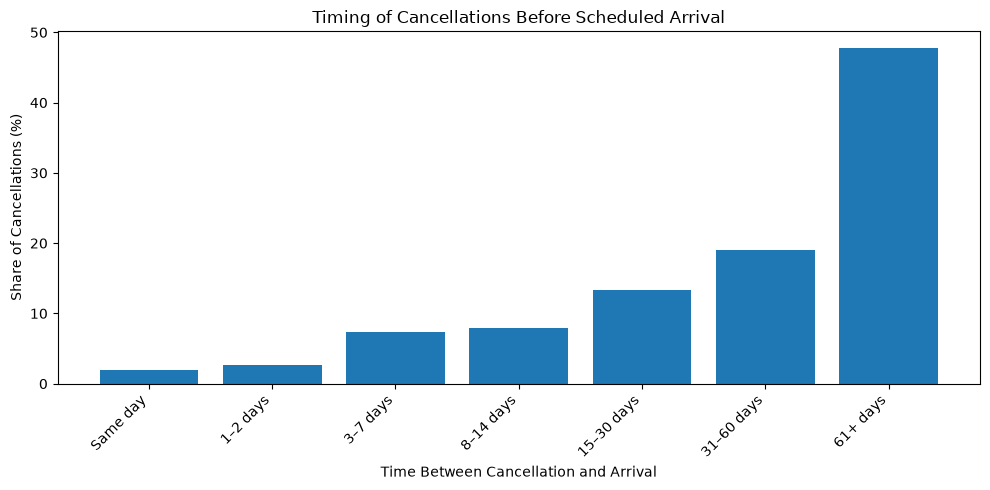

In [31]:
timing_bins = [
    -0.1,
    0,
    2,
    7,
    14,
    30,
    60,
    np.inf
]

timing_labels = [
    "Same day",
    "1–2 days",
    "3–7 days",
    "8–14 days",
    "15–30 days",
    "31–60 days",
    "61+ days"
]

valid_cancellations["timing_band"] = pd.cut(
    valid_cancellations[
        "days_before_arrival"
    ],
    bins=timing_bins,
    labels=timing_labels
)

timing_distribution = (
    valid_cancellations[
        "timing_band"
    ]
    .value_counts(sort=False)
    .rename_axis("Timing Band")
    .reset_index(name="Cancellations")
)

timing_distribution["Percent"] = (
    timing_distribution["Cancellations"]
    / timing_distribution[
        "Cancellations"
    ].sum()
    * 100
).round(2)

display(timing_distribution)

fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.bar(
    timing_distribution[
        "Timing Band"
    ].astype(str),
    timing_distribution[
        "Percent"
    ]
)

ax.set_title(
    "Timing of Cancellations Before Scheduled Arrival"
)

ax.set_xlabel(
    "Time Between Cancellation and Arrival"
)

ax.set_ylabel(
    "Share of Cancellations (%)"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

### 4.3 Fall-through by hotel and over time

The overall fall-through rate is material, but this does not show whether the problem affects both hotels similarly or whether it is concentrated in particular periods.

This section compares reservation fall-through across hotels and arrival periods to assess whether the issue is persistent enough to support a general predictive solution.

In [32]:
# Temporary fall-through flag for EDA

cancel_mapping = {
    "0": 0,
    "no": 0,
    "false": 0,
    "1": 1,
    "yes": 1,
    "true": 1
}

bookings_eda["fall_through_flag"] = (
    bookings_eda["is_canceled"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(cancel_mapping)
)

print(
    "Unmapped fall-through values:",
    bookings_eda["fall_through_flag"].isna().sum()
)

Unmapped fall-through values: 0


In [33]:
hotel_outcomes = (
    bookings_eda
    .groupby("hotel")
    .agg(
        Bookings=("booking_id", "size"),
        Fall_Throughs=("fall_through_flag", "sum")
    )
    .reset_index()
)

hotel_outcomes["Fall_Through_Rate_Pct"] = (
    hotel_outcomes["Fall_Throughs"]
    / hotel_outcomes["Bookings"]
    * 100
).round(2)

hotel_outcomes

,hotel,Bookings,Fall_Throughs,Fall_Through_Rate_Pct
0,Airport Hotel,39208,10818,27.59
1,City Hotel,78988,32210,40.78


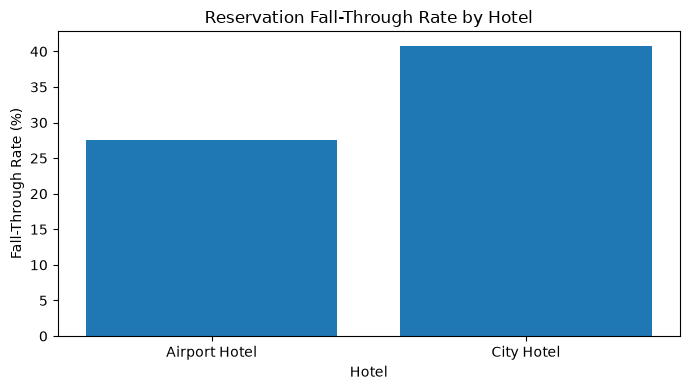

In [34]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    hotel_outcomes["hotel"],
    hotel_outcomes["Fall_Through_Rate_Pct"]
)

ax.set_title("Reservation Fall-Through Rate by Hotel")
ax.set_xlabel("Hotel")
ax.set_ylabel("Fall-Through Rate (%)")

plt.tight_layout()
plt.show()

In [35]:
bookings_eda["arrival_period"] = (
    bookings_eda["arrival_date"]
    .dt.to_period("M")
)

monthly_outcomes = (
    bookings_eda
    .groupby("arrival_period")
    .agg(
        Bookings=("booking_id", "size"),
        Fall_Throughs=("fall_through_flag", "sum")
    )
    .reset_index()
)

monthly_outcomes["Fall_Through_Rate_Pct"] = (
    monthly_outcomes["Fall_Throughs"]
    / monthly_outcomes["Bookings"]
    * 100
)

monthly_outcomes["arrival_period"] = (
    monthly_outcomes["arrival_period"]
    .astype(str)
)

monthly_outcomes

,arrival_period,Bookings,Fall_Throughs,Fall_Through_Rate_Pct
0,2023-08,3883,1598,41.15
1,2023-09,5109,2093,40.97
2,2023-10,4951,1732,34.98
3,2023-11,2337,486,20.80
4,2023-12,2913,973,33.40
5,2024-01,2248,557,24.78
6,2024-02,3884,1335,34.37
7,2024-03,6580,1565,23.78
8,2024-04,5425,2060,37.97
9,2024-05,5475,1915,34.98


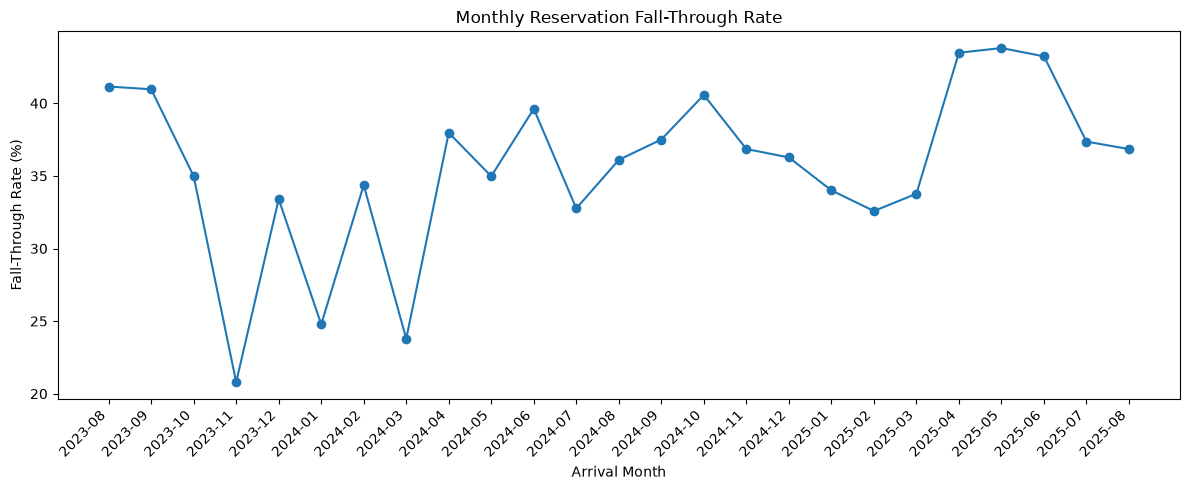

In [36]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_outcomes["arrival_period"],
    monthly_outcomes["Fall_Through_Rate_Pct"],
    marker="o"
)

ax.set_title("Monthly Reservation Fall-Through Rate")
ax.set_xlabel("Arrival Month")
ax.set_ylabel("Fall-Through Rate (%)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Interpretation:** Fall-through is materially higher at City Hotel (40.78%) than at Airport Hotel (27.59%).

The monthly pattern also shows that fall-through remains material throughout the observed period rather than being driven by a single isolated month. This suggests that reservation fall-through is a persistent issue, although its magnitude varies across property and time.

Hotel and arrival-period characteristics may therefore contain useful information for predictive modelling.

In [37]:
def normalize_category(series):
    return (
        series
        .astype("string")
        .fillna("")
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
    )


missing_like = {
    "",
    "-",
    "unknown",
    "undefined",
    "na",
    "n/a",
    "null",
    "nan"
}

In [38]:
deposit_norm = (
    normalize_category(bookings_eda["deposit_type"])
    .str.replace("-", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
)

bookings_eda["deposit_type_eda"] = deposit_norm.map(
    lambda x:
        "No Deposit" if x in {"no deposit", "no depost"}
        else "Non Refund" if x == "non refund"
        else "Refundable" if x == "refundable"
        else "Unknown" if x in missing_like
        else x.title()
)

In [39]:
market_norm = (
    normalize_category(bookings_eda["market_segment"])
    .str.replace("-", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
)

def map_market_segment(x):
    compact = x.replace(" ", "")

    if compact in {"onlineta", "onlinta"}:
        return "Online TA"

    if compact in {"offlineta/to", "offlineta/t0"}:
        return "Offline TA/TO"

    if x == "groups":
        return "Groups"

    if x == "direct":
        return "Direct"

    if x == "corporate":
        return "Corporate"

    if x == "complementary":
        return "Complementary"

    if x == "aviation":
        return "Aviation"

    if x in missing_like:
        return "Unknown"

    return x.title()


bookings_eda["market_segment_eda"] = (
    market_norm.map(map_market_segment)
)

In [40]:
channel_norm = normalize_category(
    bookings_eda["distribution_channel"]
)

def map_distribution_channel(x):
    if x == "ta/to":
        return "TA/TO"

    if x == "direct":
        return "Direct"

    if x == "corporate":
        return "Corporate"

    if x == "gds":
        return "GDS"

    if x in missing_like:
        return "Unknown"

    return x.title()


bookings_eda["distribution_channel_eda"] = (
    channel_norm.map(map_distribution_channel)
)

In [41]:
customer_norm = normalize_category(
    bookings_eda["customer_type"]
)

def map_customer_type(x):
    if x in {"transient", "transiant"}:
        return "Transient"

    if x in {"transient-party", "transient party"}:
        return "Transient-Party"

    if x == "contract":
        return "Contract"

    if x == "group":
        return "Group"

    if x in missing_like:
        return "Unknown"

    return x.title()


bookings_eda["customer_type_eda"] = (
    customer_norm.map(map_customer_type)
)

### 4.4 Cancellation versus no-show

The proposed `fall_through_flag` combines cancellations and no-shows because both result in a confirmed reservation not becoming a completed stay.

However, no-shows may represent different customer behaviour from advance cancellations. Their frequency and booking characteristics are therefore compared before deciding whether a combined binary target is appropriate.

In [42]:
fall_through_types = (
    bookings_eda.loc[
        bookings_eda["reservation_status"]
        .isin(["Canceled", "No-Show"])
    ]
    ["reservation_status"]
    .value_counts()
    .rename_axis("Outcome")
    .reset_index(name="Bookings")
)

fall_through_types["Percent_of_Fall_Throughs"] = (
    fall_through_types["Bookings"]
    / fall_through_types["Bookings"].sum()
    * 100
).round(2)

fall_through_types

,Outcome,Bookings,Percent_of_Fall_Throughs
0,Canceled,41849,97.26
1,No-Show,1179,2.74


In [43]:
pd.crosstab(
    bookings_eda["reservation_status"],
    bookings_eda["hotel"],
    normalize="index"
).loc[["Canceled", "No-Show"]].round(3)

hotel,Airport Hotel,City Hotel
reservation_status,,
Canceled,0.25,0.75
No-Show,0.24,0.76


In [44]:
status_segment = pd.crosstab(
    bookings_eda["reservation_status"],
    bookings_eda["market_segment_eda"],
    normalize="index"
)

status_segment.loc[
    ["Canceled", "No-Show"]
].round(3)

market_segment_eda,,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Unknown
reservation_status,,,,,,,,,
Canceled,0.00,0.00,0.00,0.02,0.04,0.27,0.19,0.47,0.00
No-Show,0.00,0.01,0.01,0.06,0.17,0.06,0.19,0.49,0.00


In [45]:
status_channel = pd.crosstab(
    bookings_eda["reservation_status"],
    bookings_eda["distribution_channel_eda"],
    normalize="index"
)

status_channel.loc[
    ["Canceled", "No-Show"]
].round(3)

distribution_channel_eda,Corporate,Direct,GDS,TA/TO,Unknown
reservation_status,,,,,
Canceled,0.03,0.06,0.00,0.91,0.00
No-Show,0.08,0.18,0.00,0.73,0.00


**Interpretation:** Cancellations account for 97.26% of reservation fall-throughs, while no-shows represent only 2.74%.

The hotel distribution is similar across the two outcomes, but some booking-channel characteristics differ. In particular, cancellations are more concentrated among Group bookings, while no-shows have relatively greater representation among Direct and Corporate bookings.

This suggests that cancellations and no-shows are not behaviourally identical. However, because no-shows represent only a small proportion of total fall-throughs, a combined binary fall-through target may still be practical for modelling. This decision will be considered together with the remaining EDA evidence.

### 4.5 Booking-time characteristics associated with fall-through

A predictive model is only useful if information available before the reservation outcome contains signal related to fall-through.

This section therefore examines a focused set of booking-time characteristics. Outcome fields and information that may only become available later in the reservation lifecycle are excluded from this analysis.

In [46]:
def fall_through_summary(df, column, min_bookings=100):
    summary = (
        df.groupby(column, dropna=False)
        .agg(
            Bookings=("booking_id", "size"),
            Fall_Throughs=("fall_through_flag", "sum")
        )
        .reset_index()
    )

    summary["Fall_Through_Rate_Pct"] = (
        summary["Fall_Throughs"]
        / summary["Bookings"]
        * 100
    ).round(2)

    return (
        summary.loc[
            summary["Bookings"] >= min_bookings
        ]
        .sort_values(
            "Fall_Through_Rate_Pct",
            ascending=False
        )
    )

In [47]:
display(
    fall_through_summary(
        bookings_eda,
        "deposit_type_eda"
    )
)

,deposit_type_eda,Bookings,Fall_Throughs,Fall_Through_Rate_Pct
1,Non Refund,14356,14263,99.35
0,No Deposit,103678,28729,27.71
2,Refundable,162,36,22.22


In [48]:
display(
    fall_through_summary(
        bookings_eda,
        "market_segment_eda"
    )
)

,market_segment_eda,Bookings,Fall_Throughs,Fall_Through_Rate_Pct
5,Groups,18980,11364,59.87
7,Online TA,56495,20352,36.02
6,Offline TA/TO,23462,8124,34.63
8,Unknown,401,136,33.92
1,Aviation,235,52,22.13
3,Corporate,5233,984,18.80
4,Direct,12599,1906,15.13
2,Complementary,716,86,12.01


In [49]:
display(
    fall_through_summary(
        bookings_eda,
        "distribution_channel_eda"
    )
)

,distribution_channel_eda,Bookings,Fall_Throughs,Fall_Through_Rate_Pct
3,TA/TO,96327,38850,40.33
4,Unknown,499,168,33.67
0,Corporate,6599,1457,22.08
2,GDS,192,37,19.27
1,Direct,14579,2516,17.26


In [50]:
display(
    fall_through_summary(
        bookings_eda,
        "customer_type_eda"
    )
)

,customer_type_eda,Bookings,Fall_Throughs,Fall_Through_Rate_Pct
2,Transient,89069,35882,40.29
4,Unknown,537,196,36.50
0,Contract,3695,1036,28.04
3,Transient-Party,24331,5856,24.07
1,Group,564,58,10.28


In [51]:
lead_time_text = (
    bookings_eda["lead_time"]
    .astype("string")
    .str.strip()
)

bookings_eda["lead_time_num"] = pd.to_numeric(
    lead_time_text
    .str.extract(r"(-?\d+(?:\.\d+)?)")[0],
    errors="coerce"
)

lead_time_quality = pd.DataFrame({
    "Metric": [
        "Unparsed lead_time values",
        "Negative lead_time values",
        "Minimum lead_time",
        "Maximum lead_time"
    ],
    "Value": [
        bookings_eda["lead_time_num"].isna().sum(),
        (bookings_eda["lead_time_num"] < 0).sum(),
        bookings_eda["lead_time_num"].min(),
        bookings_eda["lead_time_num"].max()
    ]
})

lead_time_quality

,Metric,Value
0,Unparsed lead_time values,0
1,Negative lead_time values,300
2,Minimum lead_time,-30
3,Maximum lead_time,4989


In [52]:
# Negative lead times are not logically valid for this analysis,
# so they are excluded from the lead-time relationship only.

lead_time_eda = bookings_eda.loc[
    bookings_eda["lead_time_num"] >= 0
].copy()

lead_time_bins = [
    -0.1,
    7,
    30,
    60,
    90,
    180,
    365,
    np.inf
]

lead_time_labels = [
    "0–7 days",
    "8–30 days",
    "31–60 days",
    "61–90 days",
    "91–180 days",
    "181–365 days",
    "366+ days"
]

lead_time_eda["lead_time_band"] = pd.cut(
    lead_time_eda["lead_time_num"],
    bins=lead_time_bins,
    labels=lead_time_labels
)

lead_time_outcomes = fall_through_summary(
    lead_time_eda,
    "lead_time_band",
    min_bookings=1
)

lead_time_outcomes

,lead_time_band,Bookings,Fall_Throughs,Fall_Through_Rate_Pct
6,366+ days,3230,2160,66.87
5,181–365 days,20631,11299,54.77
4,91–180 days,25686,11461,44.62
3,61–90 days,12256,4845,39.53
2,31–60 days,16575,6043,36.46
1,8–30 days,19776,5217,26.38
0,0–7 days,19742,1881,9.53


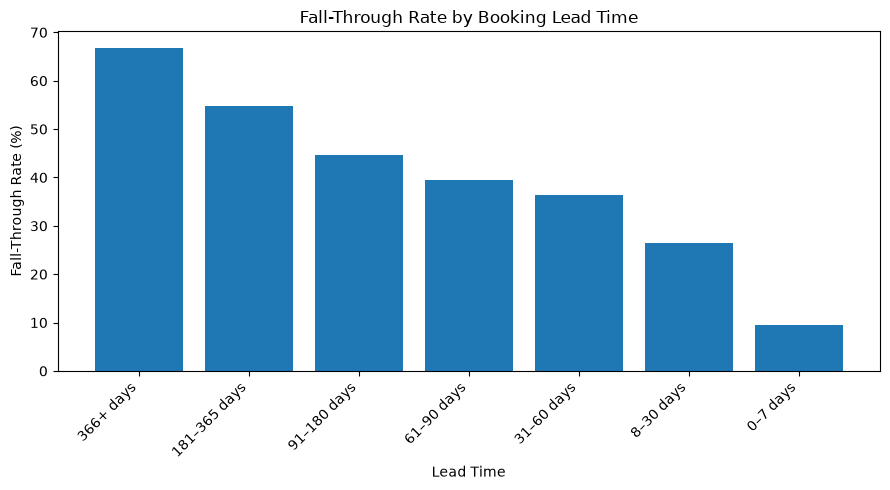

In [53]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    lead_time_outcomes["lead_time_band"].astype("string"),
    lead_time_outcomes["Fall_Through_Rate_Pct"]
)

ax.set_title("Fall-Through Rate by Booking Lead Time")
ax.set_xlabel("Lead Time")
ax.set_ylabel("Fall-Through Rate (%)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Interpretation:** Several characteristics available at or near booking time show substantial differences in historical fall-through rates.

Non-refundable bookings have a particularly high fall-through rate (99.35%), while market segment, distribution channel and customer type also show meaningful variation. Group bookings show a notably higher fall-through rate than several other market segments.

Lead time also shows a strong relationship with the outcome: fall-through rises progressively as bookings are made further in advance, from 9.53% for bookings made within 0–7 days to 66.87% for bookings made more than 365 days before arrival.

These relationships do not establish causality or guarantee predictive performance, but they indicate that information available before the eventual reservation outcome contains potentially useful predictive signal.

### 4.6 Pricing and ADR feasibility

Pricing is another business concern raised by the stakeholder. This section briefly examines historical Average Daily Rate (ADR) patterns to determine whether the available data provides a suitable basis for a pricing-focused machine learning problem.

The purpose is not to construct a pricing model at this stage, but to compare the strength of the available pricing evidence against the reservation fall-through opportunity.

In [54]:
adr_text = (
    bookings_eda["adr"]
    .astype("string")
    .str.strip()
    .str.replace("SGD", "", case=False, regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip()
)

bookings_eda["adr_num"] = pd.to_numeric(
    adr_text,
    errors="coerce"
)

print(
    "Unparsed ADR rows:",
    bookings_eda["adr_num"].isna().sum()
)

Unparsed ADR rows: 0


In [55]:
adr_by_hotel = (
    bookings_eda
    .groupby("hotel")
    ["adr_num"]
    .agg(
        ["count", "median", "mean"]
    )
    .round(2)
)

adr_by_hotel

,count,median,mean
hotel,,,
Airport Hotel,39208,172.50,221.99
City Hotel,78988,230.00,278.18


In [56]:
monthly_adr = (
    bookings_eda
    .groupby("arrival_month_num")
    ["adr_num"]
    .median()
    .reset_index(name="Median_ADR")
)

monthly_adr

,arrival_month_num,Median_ADR
0,1,163.30
1,2,172.50
2,3,195.50
3,4,221.49
4,5,248.40
5,6,264.50
6,7,287.50
7,8,300.15
8,9,230.69
9,10,197.04


**Interpretation:** ADR varies across the two properties and across arrival months, confirming that pricing is an important operational dimension of the business.

However, the available data records historical prices rather than an observed optimal price. It does not provide key information such as competitor rates, rejected bookings, unconstrained demand, real-time room availability or experimentally observed price elasticity.

Therefore, while pricing remains relevant to the business problem, the dataset provides a less clearly defined supervised-learning target for price optimisation than it does for reservation fall-through prediction.

### 4.7 Guest reviews and modelling relevance

The dataset also includes post-stay guest reviews. These may provide useful context on customer experience and perceived value, but their relationship to reservation outcomes must be understood before considering them for modelling.

Because reviews are collected after a stay, they are not expected to be available when predicting whether a current reservation will fall through.

In [57]:
reviews_eda = reviews.drop_duplicates().copy()

review_summary = pd.DataFrame({
    "Metric": [
        "Raw review rows",
        "Rows after exact duplicate removal",
        "Unique review customers",
        "Blank comments"
    ],
    "Value": [
        len(reviews),
        len(reviews_eda),
        reviews_eda["client_email"].nunique(),
        reviews_eda["comments"]
        .astype("string")
        .str.strip()
        .eq("")
        .sum()
    ]
})

review_summary

,Metric,Value
0,Raw review rows,17583
1,Rows after exact duplicate removal,17532
2,Unique review customers,17532
3,Blank comments,332


In [58]:
reviews_eda["rating_num"] = pd.to_numeric(
    reviews_eda["rating"],
    errors="coerce"
)

rating_counts = (
    reviews_eda["rating_num"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("Rating")
    .reset_index(name="Reviews")
)

rating_counts

,Rating,Reviews
0,0,86
1,1,99
2,2,526
3,3,1550
4,4,10603
5,5,4581
6,6,87


In [59]:
invalid_rating_mask = ~reviews_eda["rating_num"].between(1, 5)

print(
    "Ratings outside documented 1–5 range:",
    invalid_rating_mask.sum()
)

print(
    "Percent outside documented range:",
    round(
        invalid_rating_mask.mean() * 100,
        2
    )
)

Ratings outside documented 1–5 range: 173
Percent outside documented range: 0.99


In [60]:
review_link = (
    bookings_eda[
        [
            "booking_id",
            "client_email",
            "reservation_status"
        ]
    ]
    .merge(
        reviews_eda[
            [
                "client_email",
                "rating_num",
                "comments"
            ]
        ],
        on="client_email",
        how="inner",
        validate="one_to_one"
    )
)

print(
    "Matched reviewed reservations:",
    len(review_link)
)

display(
    review_link[
        "reservation_status"
    ].value_counts()
)

Matched reviewed reservations: 17532


reservation_status
Check-Out    17532
Name: count, dtype: int64

**Interpretation:** After removing exact duplicate review records, 17,532 unique reviews remain. All reviewed reservations correspond to completed `Check-Out` stays.

This confirms that review information is outcome-selected and post-stay. Rating, comments and even the existence of a review would therefore introduce leakage if used to predict whether the same reservation will cancel or no-show.

The rating field also contains 173 observations outside its documented 1–5 range (`0` or `6`), indicating an additional data-quality issue.

Reviews remain useful as contextual evidence about completed-stay customer experience, but they will not be used as predictors in the reservation fall-through model.

## 5. ML Problem Selection

### 5.1 Problem selection and rationale

The business raised two primary opportunities for machine learning: reducing the impact of reservation fall-through and improving room pricing.

The EDA indicates that reservation fall-through is the stronger problem for the available dataset.

After excluding known exact duplicate source records, 36.40% of reservations did not result in a completed stay. The issue is persistent across the observed period and affects both properties, although City Hotel has a substantially higher fall-through rate than Airport Hotel.

The cancellation-timing analysis only partially supports the stakeholder's concern that cancellations are predominantly last-minute. Median cancellation notice is 56 days before arrival, while only 12.04% of cancellations occur within seven days. The opportunity is therefore better framed as providing earlier visibility of future reservation risk rather than primarily supporting last-minute room recovery.

Several characteristics available before the reservation outcome show substantial differences in historical fall-through rate, including lead time, deposit type, market segment, distribution channel and customer type. This provides evidence that pre-outcome booking information may contain useful predictive signal.

Pricing remains commercially important, and historical ADR varies across hotels and arrival periods. However, the dataset contains historical prices rather than an observed optimal price and does not include information such as competitor rates, rejected demand, real-time inventory or experimentally observed price elasticity. Predicting historical ADR would therefore risk reproducing past pricing decisions rather than identifying better prices.

Based on these findings, reservation fall-through prediction is selected as the machine learning problem for this assessment.

### 5.2 Final problem statement

Develop a supervised classification model that estimates, once a reservation has been confirmed and before its final outcome is known, the probability that the reservation will fall through rather than result in a completed stay.

The predicted risk is intended to give Travelers' Inn's Revenue & Reservations team earlier visibility of future inventory and revenue exposure so that high-risk reservations can be identified for proactive operational planning.

### 5.3 Target definition

The modelling target is a binary `fall_through_flag` based on the final reservation outcome:

- `0` — `Check-Out`: the reservation resulted in a completed stay.
- `1` — `Canceled` or `No-Show`: the reservation did not result in a completed stay.

Cancellations account for 97.26% of the positive class and no-shows account for 2.74%.

Although cancellations and no-shows are not behaviourally identical, they are combined because both represent the same high-level operational outcome: reserved inventory not becoming a completed stay. The relatively small number of no-shows also makes a standalone no-show modelling task less attractive.

Model performance on cancellations and no-shows should nevertheless be reviewed separately so that aggregate performance does not hide poor performance on the smaller no-show subgroup.

### 5.4 Prediction point and leakage boundary

The intended prediction point is when a reservation has been confirmed, before its eventual cancellation, no-show or completed stay is known.

Only information reasonably available by this point should be eligible as predictive features.

The following fields will therefore be excluded from the predictive feature set:

- `reservation_status` — directly represents the final outcome.
- `reservation_status_date` — records when the final outcome was set.
- `assigned_room_type` — represents the room actually assigned at check-in.
- `booking_changes` — the final value may include amendments occurring after confirmation.
- review `rating` and `comments` — post-stay information.
- review availability — all reviews belong to completed stays and would therefore leak outcome information.
- `booking_id` — reservation identifier rather than a generalisable predictor.
- `client_email` — high-cardinality customer identifier and personally identifying information.

Candidate predictors will instead focus on booking information available by confirmation time, such as hotel, lead time, arrival timing, party/stay characteristics, customer history, reserved room type, deposit type, booking channel, customer type, ADR and special requests.

### 5.5 EDA conclusion and modelling implications

The EDA supports reservation fall-through prediction as a measurable and actionable machine learning problem.

The outcome is sufficiently common to provide a meaningful modelling target, occurs across both hotels and throughout the observed period, and shows substantial variation across several pre-outcome booking characteristics.

The analysis also identified preprocessing requirements that must be reproduced in the end-to-end pipeline, including exact duplicate removal, inconsistent categorical labels, malformed numeric formats, inconsistent date formats, invalid negative lead times, and normalization of the binary target.

Because the model is intended to predict future reservations using historical data, model development should also account for the temporal nature of the dataset rather than relying only on a purely random train/test split.

The next stage therefore develops and evaluates an end-to-end classification pipeline using only leakage-safe information available before the final reservation outcome.